# Visualize Rates
### Import libraries

In [1]:
import os
import sys
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm.notebook import tqdm

Global paths

In [2]:
# Current Working Directory
CWD = os.getcwd()
# WORKSPACE
WORKSPACE = os.environ['WORKSPACE_PATH']

In [3]:
# PyCOMET
PyCOMET = WORKSPACE + '/ML/PyCOMET/pycomet/'
if importlib.util.find_spec('pycomet') is None:
    sys.path.append(os.path.abspath(PyCOMET))

In [4]:
# SurQCT
SurQCT = WORKSPACE + '/ML/PyCOMET/pycomet/examples/SurQCT/'
sys.path.append(os.path.abspath(SurQCT))

Case-specific paths

In [5]:
# Output directory# Output directory
out_dir = CWD + '/Output/VisualizeRates/'
if not os.path.exists(out_dir):
    os.makedirs(out_dir)

pcm_dir = WORKSPACE + '/ML/PyCOMET/run/SurQCT/O3_UMN/final/Diss/configs.ln/config.01/run.01/'
sqct_dir = WORKSPACE + '/ML/PyCOMET/run/SurQCT/O3_UMN/final/Diss/datagen/genTrainData/'

### Initialize PyCOMET model
Working case

In [6]:
os.chdir(pcm_dir)
sys.path.append(os.path.abspath(pcm_dir))

Import additional libraries

In [7]:
from pycomet.utilities import utils
from pycomet.apps import functions as fun
# Inputs
import inputs
from inputs.general import flags

Compile model

In [8]:
# Load network architecture
net = fun._net(
    input_mod=inputs
)
# Finalize model
for k in ('train', 'save'):
    flags[k] = 0
flags['load'] = 1
model = fun._model(
    flags=flags,
    input_mod=inputs,
    net=net
)


[PyCOMET]: Initializing 'FFNN' network ...

[PyCOMET]: Building 'FFNN' network ...
Model: "SurQCT_FFNN"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 3)]               0         
_________________________________________________________________
normalization (Normalization (None, 3)                 7         
_________________________________________________________________
ff_block (FFBlock)           (None, 1)                 625       
Total params: 632
Trainable params: 625
Non-trainable params: 7
_________________________________________________________________
[PyCOMET]:   Restoring network from file 'saving/SurQCT_FFNN.h5'
[PyCOMET]:   >> Function 'build' took 0:00:00.218717


In [9]:
os.chdir(CWD)

### Initialize SurQCT parameters

Import additional libraries

In [10]:
from surqct.src.chemical_systems import systems as syst
from surqct.src.rates_type.rates_type import RatesType
from surqct.src.utilities import const
from surqct import config as cfg

SurQCT model inputs

In [11]:
sys.path.append(os.path.dirname(sqct_dir))
import InputData

In [12]:
TTranVec = [1500, 2500, 5000, 8000, 10000, 12000, 15000, 20000]

Initializing chemical system and rates type module

In [13]:
Systems = {}
Systems['SurQCT'] = syst.get_system(
    NameLong=InputData.SystemName,
    ProcNames=InputData.RatesType
)
rates_type = RatesType(Systems['SurQCT'], InputData)
MolIn = Systems['SurQCT'].Processes.CompInOut[InputData.RatesType]['In'][0]

In [14]:
Systems['QCT'] = syst.get_system(
    NameLong=InputData.SystemName,
    KinSource='QCT',
    ProcNames=tf.nest.flatten(InputData.RatesType),
    PathToHDF5Fld=cfg.paths.HDF5Dtb + '/QCT/Orig/'
)
Systems['QCT'].Processes.read_rates(TTranVec=TTranVec)

Sampling levels

In [15]:
# Predefined
TTranVec = [300, 1500, 2500, 5000, 8000, 10000, 12000, 15000, 20000, 50000]
InputData.iLevelsVecTest = np.arange(MolIn.NLevels)

Generate testing data

In [16]:
xPred, yPred = rates_type.generate_predictiondata(
    Model=model.net,
    Columns=inputs.data.columns['x'],
    TTranVec=TTranVec
)


[SurQCT]: Generating Prediction data points ...
[SurQCT]:   Reading Variables ['log_ECB', 'log_rOut', 'log_rMax', 'ECB']
[SurQCT]:   Translational Temperature: T = 300 K
[SurQCT]:   Translational Temperature: T = 1500 K
[SurQCT]:   Translational Temperature: T = 2500 K
[SurQCT]:   Translational Temperature: T = 5000 K
[SurQCT]:   Translational Temperature: T = 8000 K
[SurQCT]:   Translational Temperature: T = 10000 K
[SurQCT]:   Translational Temperature: T = 12000 K
[SurQCT]:   Translational Temperature: T = 15000 K
[SurQCT]:   Translational Temperature: T = 20000 K
[SurQCT]:   Translational Temperature: T = 50000 K


Temperature: 300 K


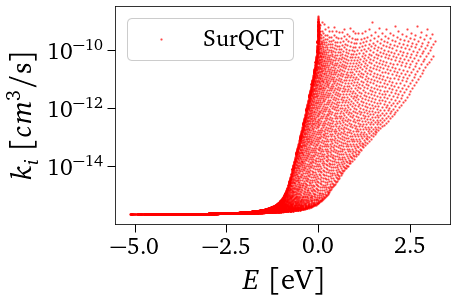

Temperature: 1500 K


<Figure size 432x288 with 0 Axes>

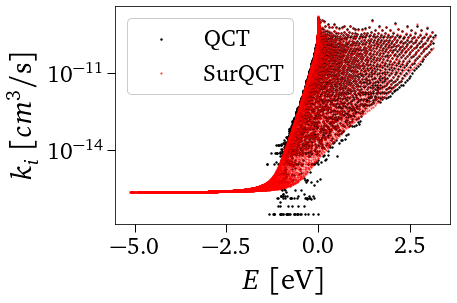

Temperature: 2500 K


<Figure size 432x288 with 0 Axes>

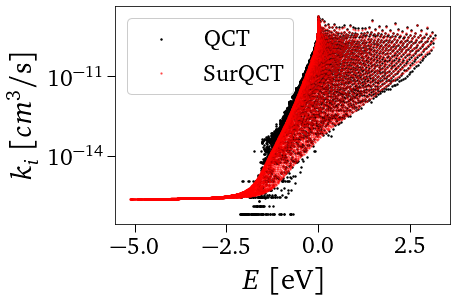

Temperature: 5000 K


<Figure size 432x288 with 0 Axes>

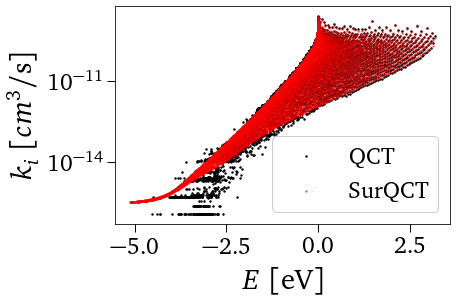

Temperature: 8000 K


<Figure size 432x288 with 0 Axes>

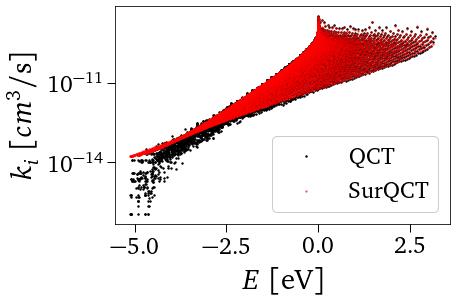

Temperature: 10000 K


<Figure size 432x288 with 0 Axes>

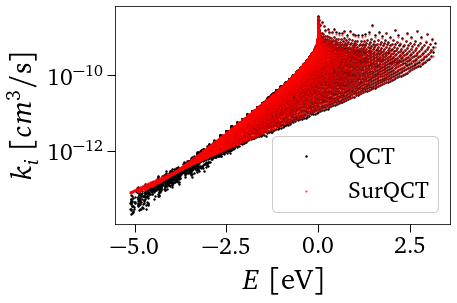

Temperature: 12000 K


<Figure size 432x288 with 0 Axes>

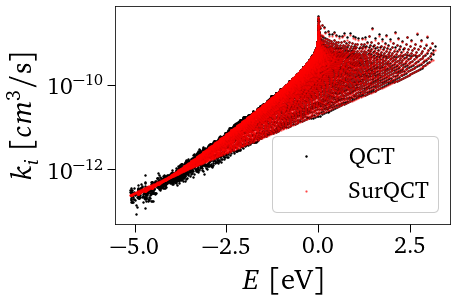

Temperature: 15000 K


<Figure size 432x288 with 0 Axes>

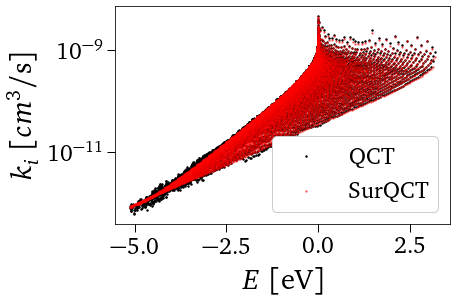

Temperature: 20000 K


<Figure size 432x288 with 0 Axes>

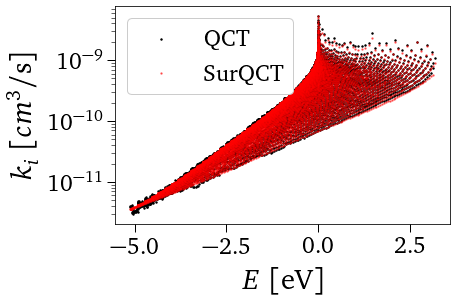

Temperature: 50000 K


<Figure size 432x288 with 0 Axes>

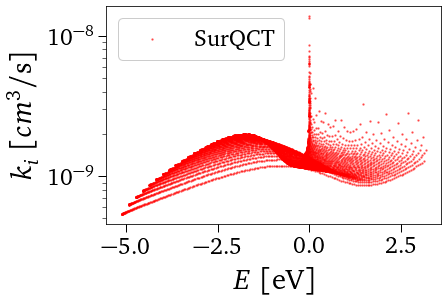

<Figure size 432x288 with 0 Axes>

In [17]:
for T in TTranVec:
    TStr     = str(int(T))
    NLevels  = Systems['QCT'].Processes.CompInOut['Diss']['In'][0].NLevels
    # True data
    if TStr in Systems['QCT'].Processes.Rates['Diss']:
        TrueData = (np.arange(NLevels), Systems['QCT'].Processes.Rates['Diss'][TStr])
    else:
        TrueData = None
    # Pred data
    IdxPred = xPred.iloc[(xPred['TTran'] == T).to_numpy()].index
    PredData = (np.arange(NLevels), yPred.to_numpy()[IdxPred])
    print(f'Temperature: {T} K')
    rates_type.plot_prediction2D(Path='./', PredData=PredData, TrueData=TrueData)